In [289]:
import pandas as pd
import numpy as np 
import matplotlib.pyplot as plt
import seaborn as sns

In [290]:
df=pd.read_csv('cardekho.csv')

In [291]:
df.head()

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage(km/ltr/kg),engine,max_power,seats
0,Maruti Swift Dzire VDI,2014,450000,145500,Diesel,Individual,Manual,First Owner,23.40,1248.0,74,5.0
1,Skoda Rapid 1.5 TDI Ambition,2014,370000,120000,Diesel,Individual,Manual,Second Owner,21.14,1498.0,103.52,5.0
2,Honda City 2017-2020 EXi,2006,158000,140000,Petrol,Individual,Manual,Third Owner,17.70,1497.0,78,5.0
3,Hyundai i20 Sportz Diesel,2010,225000,127000,Diesel,Individual,Manual,First Owner,23.00,1396.0,90,5.0
4,Maruti Swift VXI BSIII,2007,130000,120000,Petrol,Individual,Manual,First Owner,16.10,1298.0,88.2,5.0


In [292]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8128 entries, 0 to 8127
Data columns (total 12 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   name                8128 non-null   object 
 1   year                8128 non-null   int64  
 2   selling_price       8128 non-null   int64  
 3   km_driven           8128 non-null   int64  
 4   fuel                8128 non-null   object 
 5   seller_type         8128 non-null   object 
 6   transmission        8128 non-null   object 
 7   owner               8128 non-null   object 
 8   mileage(km/ltr/kg)  7907 non-null   float64
 9   engine              7907 non-null   float64
 10  max_power           7913 non-null   object 
 11  seats               7907 non-null   float64
dtypes: float64(3), int64(3), object(6)
memory usage: 762.1+ KB


In [293]:
df['km_driven']=df['km_driven'].astype('float')

In [294]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8128 entries, 0 to 8127
Data columns (total 12 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   name                8128 non-null   object 
 1   year                8128 non-null   int64  
 2   selling_price       8128 non-null   int64  
 3   km_driven           8128 non-null   float64
 4   fuel                8128 non-null   object 
 5   seller_type         8128 non-null   object 
 6   transmission        8128 non-null   object 
 7   owner               8128 non-null   object 
 8   mileage(km/ltr/kg)  7907 non-null   float64
 9   engine              7907 non-null   float64
 10  max_power           7913 non-null   object 
 11  seats               7907 non-null   float64
dtypes: float64(4), int64(2), object(6)
memory usage: 762.1+ KB


In [295]:
df.isnull()

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage(km/ltr/kg),engine,max_power,seats
0,False,False,False,False,False,False,False,False,False,False,False,False
1,False,False,False,False,False,False,False,False,False,False,False,False
2,False,False,False,False,False,False,False,False,False,False,False,False
3,False,False,False,False,False,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...
8123,False,False,False,False,False,False,False,False,False,False,False,False
8124,False,False,False,False,False,False,False,False,False,False,False,False
8125,False,False,False,False,False,False,False,False,False,False,False,False
8126,False,False,False,False,False,False,False,False,False,False,False,False


In [296]:
df.isnull().sum()

name                    0
year                    0
selling_price           0
km_driven               0
fuel                    0
seller_type             0
transmission            0
owner                   0
mileage(km/ltr/kg)    221
engine                221
max_power             215
seats                 221
dtype: int64

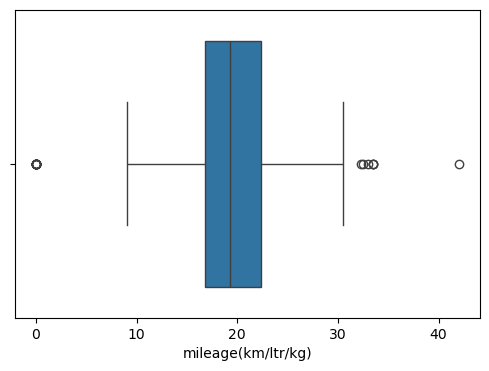

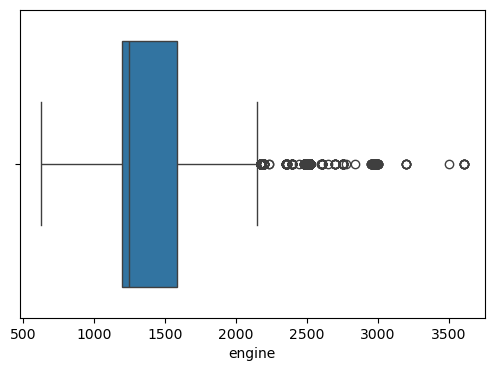

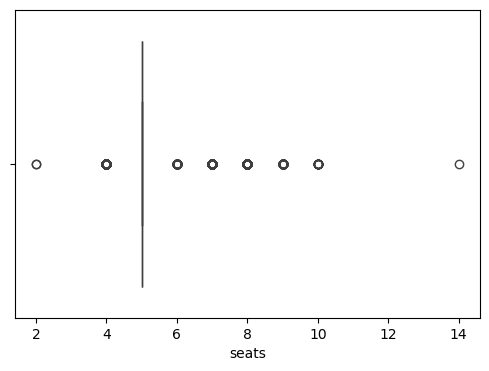

In [297]:
column=['mileage(km/ltr/kg)','engine','seats'] # checking outlier for the null value analysis
for cols in column:
    plt.figure(figsize=(6,4))
    sns.boxplot(x=df[cols])

In [298]:
# mileage and seats contains less outliers so mean can be use for fillna and median for engine cause more outliers

In [299]:
df['mileage(km/ltr/kg)'].fillna(df['mileage(km/ltr/kg)'].mean(),inplace=True)
df['seats'].fillna(df['seats'].mean(),inplace=True)
df['engine'].fillna(df['engine'].median(),inplace=True)
df['max_power'].fillna(df['max_power'].mode()[0],inplace=True)

C:\Users\ACER\AppData\Local\Temp\ipykernel_15540\3402368870.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['mileage(km/ltr/kg)'].fillna(df['mileage(km/ltr/kg)'].mean(),inplace=True)
C:\Users\ACER\AppData\Local\Temp\ipykernel_15540\3402368870.py:2: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always 

In [300]:
df.isnull().sum()

name                  0
year                  0
selling_price         0
km_driven             0
fuel                  0
seller_type           0
transmission          0
owner                 0
mileage(km/ltr/kg)    0
engine                0
max_power             0
seats                 0
dtype: int64

In [301]:
df['max_power'] = pd.to_numeric(df['max_power'].str.strip(), errors='coerce')
# converting datatype of the max_power to float from object

In [302]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8128 entries, 0 to 8127
Data columns (total 12 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   name                8128 non-null   object 
 1   year                8128 non-null   int64  
 2   selling_price       8128 non-null   int64  
 3   km_driven           8128 non-null   float64
 4   fuel                8128 non-null   object 
 5   seller_type         8128 non-null   object 
 6   transmission        8128 non-null   object 
 7   owner               8128 non-null   object 
 8   mileage(km/ltr/kg)  8128 non-null   float64
 9   engine              8128 non-null   float64
 10  max_power           8127 non-null   float64
 11  seats               8128 non-null   float64
dtypes: float64(5), int64(2), object(5)
memory usage: 762.1+ KB


In [303]:
df.duplicated().sum()

np.int64(1202)

In [304]:
# 1202 duplicate values are present so droping all the duplicate values

In [305]:
df=df.drop_duplicates()

In [306]:
df.duplicated().sum()

np.int64(0)

In [307]:
df.shape

(6926, 12)

In [308]:
df.groupby('transmission')['selling_price'].value_counts()

transmission  selling_price
Automatic     400000           14
              600000           14
              650000           12
              750000           12
              700000           11
                               ..
Manual        2125000           1
              2900000           1
              2950000           1
              3000000           1
              3200000           1
Name: count, Length: 837, dtype: int64

In [309]:
df.groupby('year')['selling_price'].value_counts()

year  selling_price
1983  300000           1
1991  55000            1
1994  45000            1
      99000            1
      120000           1
                      ..
2020  1950000          1
      2125000          1
      2300000          1
      3200000          1
      7200000          1
Name: count, Length: 2275, dtype: int64

In [310]:
df.columns

Index(['name', 'year', 'selling_price', 'km_driven', 'fuel', 'seller_type',
       'transmission', 'owner', 'mileage(km/ltr/kg)', 'engine', 'max_power',
       'seats'],
      dtype='object')

<Axes: xlabel='year'>

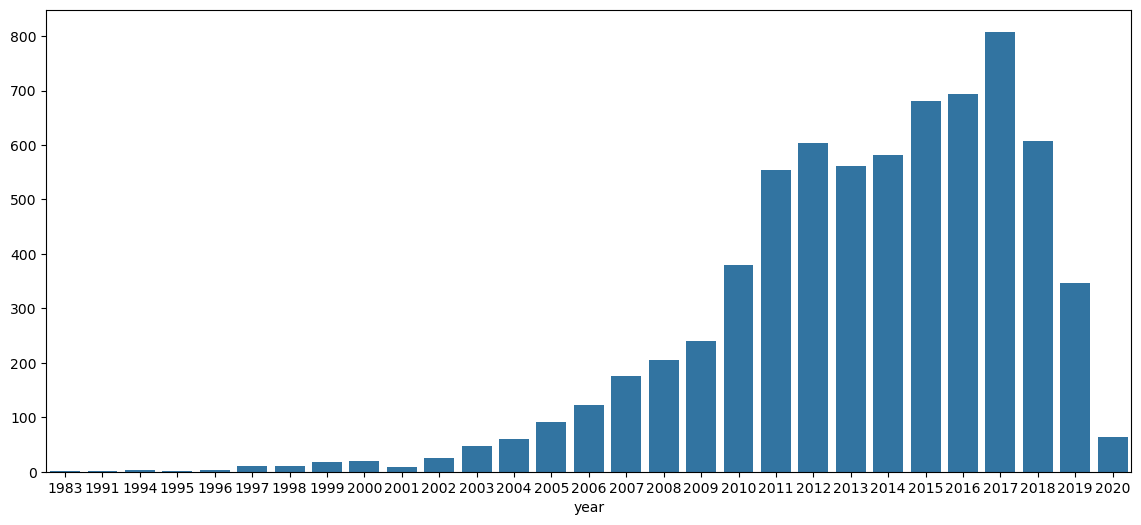

In [311]:
new=df['year'].value_counts()
plt.figure(figsize=(14,6))
sns.barplot(x=new.index, y=new.values)

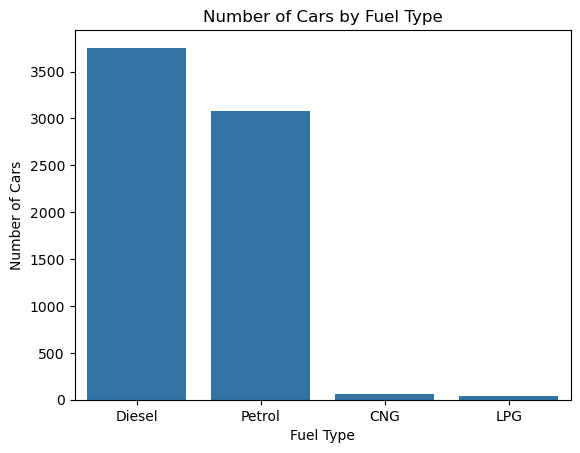

In [312]:
new = df['fuel'].value_counts().reset_index()

sns.barplot(data=new, x='fuel', y='count')

plt.xlabel('Fuel Type')
plt.ylabel('Number of Cars')
plt.title('Number of Cars by Fuel Type')
plt.show()

In [313]:
df['transmission'].value_counts()

transmission
Manual       6342
Automatic     584
Name: count, dtype: int64

In [314]:
df['owner'].value_counts()

owner
First Owner             4242
Second Owner            1974
Third Owner              536
Fourth & Above Owner     169
Test Drive Car             5
Name: count, dtype: int64

<Axes: >

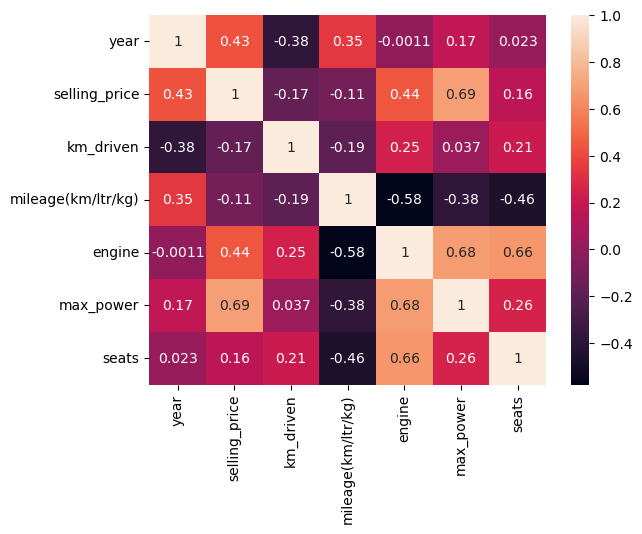

In [315]:
sns.heatmap(df.corr(numeric_only=True),annot=True)

In [316]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 6926 entries, 0 to 8125
Data columns (total 12 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   name                6926 non-null   object 
 1   year                6926 non-null   int64  
 2   selling_price       6926 non-null   int64  
 3   km_driven           6926 non-null   float64
 4   fuel                6926 non-null   object 
 5   seller_type         6926 non-null   object 
 6   transmission        6926 non-null   object 
 7   owner               6926 non-null   object 
 8   mileage(km/ltr/kg)  6926 non-null   float64
 9   engine              6926 non-null   float64
 10  max_power           6925 non-null   float64
 11  seats               6926 non-null   float64
dtypes: float64(5), int64(2), object(5)
memory usage: 703.4+ KB


In [317]:
numeric_cols=['selling_price','mileage(km/ltr/kg)','engine','seats']


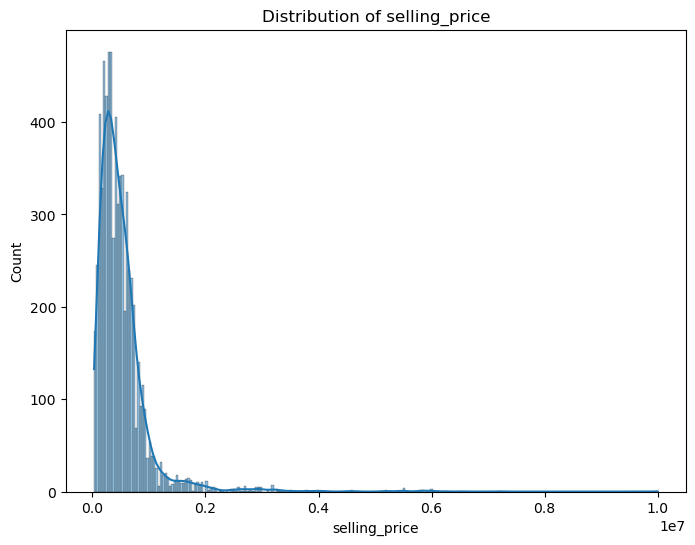

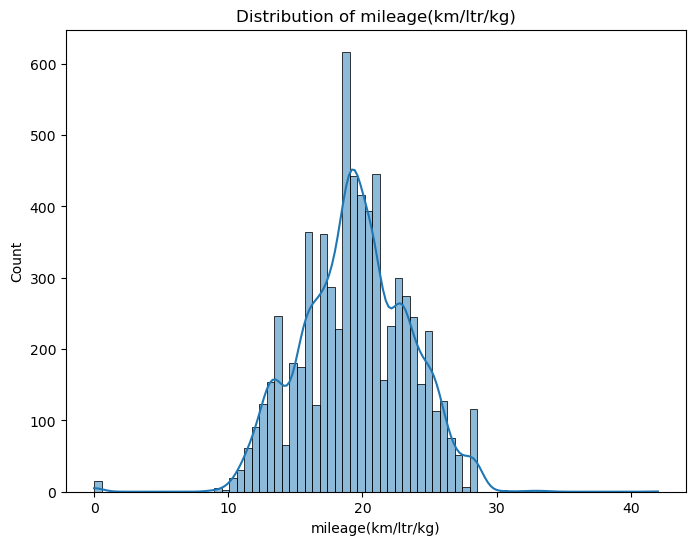

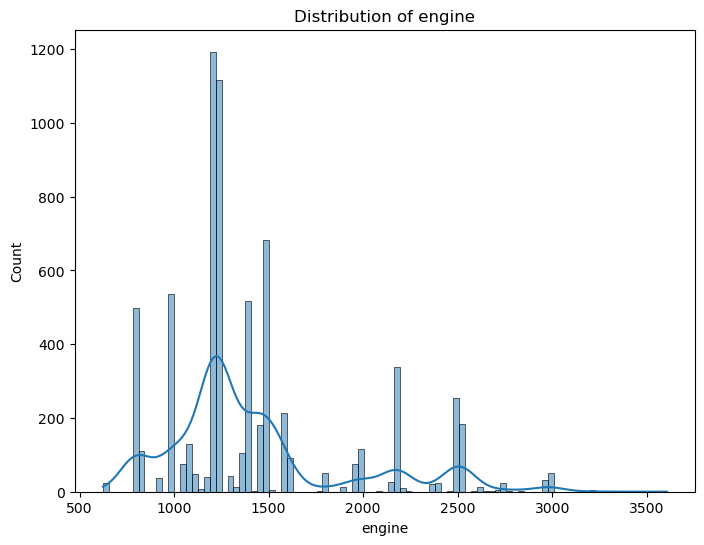

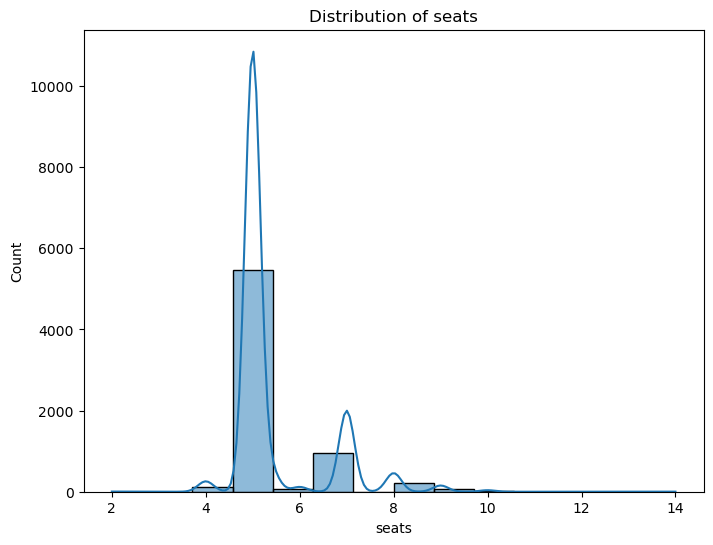

In [318]:
for cols in numeric_cols:
    plt.figure(figsize=(8, 6))
    sns.histplot(data=df, x=cols, kde=True)
    plt.title(f'Distribution of {cols}')
    plt.show()

In [319]:
df.head()

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage(km/ltr/kg),engine,max_power,seats
0,Maruti Swift Dzire VDI,2014,450000,145500.0,Diesel,Individual,Manual,First Owner,23.40,1248.0,74.00,5.0
1,Skoda Rapid 1.5 TDI Ambition,2014,370000,120000.0,Diesel,Individual,Manual,Second Owner,21.14,1498.0,103.52,5.0
2,Honda City 2017-2020 EXi,2006,158000,140000.0,Petrol,Individual,Manual,Third Owner,17.70,1497.0,78.00,5.0
3,Hyundai i20 Sportz Diesel,2010,225000,127000.0,Diesel,Individual,Manual,First Owner,23.00,1396.0,90.00,5.0
4,Maruti Swift VXI BSIII,2007,130000,120000.0,Petrol,Individual,Manual,First Owner,16.10,1298.0,88.20,5.0


In [320]:
df.isnull().sum()

name                  0
year                  0
selling_price         0
km_driven             0
fuel                  0
seller_type           0
transmission          0
owner                 0
mileage(km/ltr/kg)    0
engine                0
max_power             1
seats                 0
dtype: int64

In [321]:
df = df.dropna()

In [322]:
df['seller_type'].value_counts()# this is also not required for prediction

seller_type
Individual          6217
Dealer               681
Trustmark Dealer      27
Name: count, dtype: int64

In [323]:
df=df.drop(columns=['seller_type'])

In [324]:
df.head()

,name,year,selling_price,km_driven,fuel,transmission,owner,mileage(km/ltr/kg),engine,max_power,seats
0,Maruti Swift Dzire VDI,2014,450000,145500.0,Diesel,Manual,First Owner,23.40,1248.0,74.00,5.0
1,Skoda Rapid 1.5 TDI Ambition,2014,370000,120000.0,Diesel,Manual,Second Owner,21.14,1498.0,103.52,5.0
2,Honda City 2017-2020 EXi,2006,158000,140000.0,Petrol,Manual,Third Owner,17.70,1497.0,78.00,5.0
3,Hyundai i20 Sportz Diesel,2010,225000,127000.0,Diesel,Manual,First Owner,23.00,1396.0,90.00,5.0
4,Maruti Swift VXI BSIII,2007,130000,120000.0,Petrol,Manual,First Owner,16.10,1298.0,88.20,5.0


In [325]:
df['age']=(df['year']-2026).abs() #calculating cars age from year

In [326]:
df.head()

,name,year,selling_price,km_driven,fuel,transmission,owner,mileage(km/ltr/kg),engine,max_power,seats,age
0,Maruti Swift Dzire VDI,2014,450000,145500.0,Diesel,Manual,First Owner,23.40,1248.0,74.00,5.0,12
1,Skoda Rapid 1.5 TDI Ambition,2014,370000,120000.0,Diesel,Manual,Second Owner,21.14,1498.0,103.52,5.0,12
2,Honda City 2017-2020 EXi,2006,158000,140000.0,Petrol,Manual,Third Owner,17.70,1497.0,78.00,5.0,20
3,Hyundai i20 Sportz Diesel,2010,225000,127000.0,Diesel,Manual,First Owner,23.00,1396.0,90.00,5.0,16
4,Maruti Swift VXI BSIII,2007,130000,120000.0,Petrol,Manual,First Owner,16.10,1298.0,88.20,5.0,19


In [327]:
df['Brand_name'] = df['name'].str.split().str[0]

In [328]:
df.head()

,name,year,selling_price,km_driven,fuel,transmission,owner,mileage(km/ltr/kg),engine,max_power,seats,age,Brand_name
0,Maruti Swift Dzire VDI,2014,450000,145500.0,Diesel,Manual,First Owner,23.40,1248.0,74.00,5.0,12,Maruti
1,Skoda Rapid 1.5 TDI Ambition,2014,370000,120000.0,Diesel,Manual,Second Owner,21.14,1498.0,103.52,5.0,12,Skoda
2,Honda City 2017-2020 EXi,2006,158000,140000.0,Petrol,Manual,Third Owner,17.70,1497.0,78.00,5.0,20,Honda
3,Hyundai i20 Sportz Diesel,2010,225000,127000.0,Diesel,Manual,First Owner,23.00,1396.0,90.00,5.0,16,Hyundai
4,Maruti Swift VXI BSIII,2007,130000,120000.0,Petrol,Manual,First Owner,16.10,1298.0,88.20,5.0,19,Maruti


In [329]:
df=df.drop(columns=['name','year'])

In [330]:
df.columns

Index(['selling_price', 'km_driven', 'fuel', 'transmission', 'owner',
       'mileage(km/ltr/kg)', 'engine', 'max_power', 'seats', 'age',
       'Brand_name'],
      dtype='object')

<Axes: xlabel='selling_price', ylabel='fuel'>

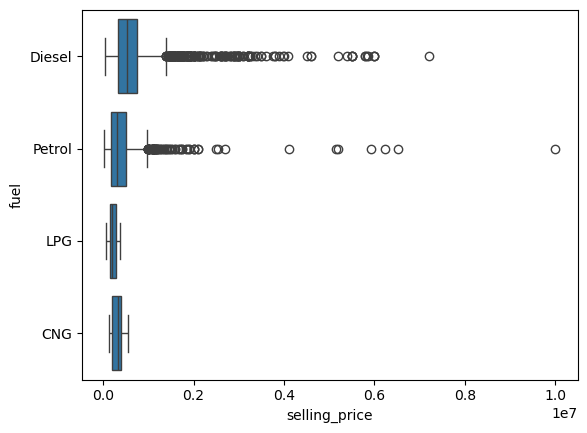

In [331]:
sns.boxplot(x=df['selling_price'],y=df['fuel'])

<Axes: xlabel='selling_price', ylabel='fuel'>

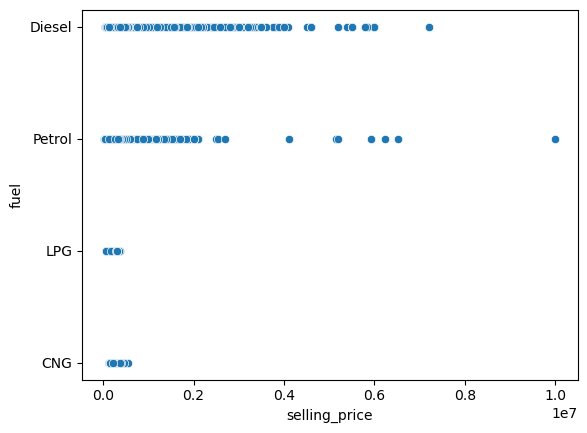

In [332]:
sns.scatterplot(x=df['selling_price'],y=df['fuel'])

In [333]:
df.head()

,selling_price,km_driven,fuel,transmission,owner,mileage(km/ltr/kg),engine,max_power,seats,age,Brand_name
0,450000,145500.0,Diesel,Manual,First Owner,23.40,1248.0,74.00,5.0,12,Maruti
1,370000,120000.0,Diesel,Manual,Second Owner,21.14,1498.0,103.52,5.0,12,Skoda
2,158000,140000.0,Petrol,Manual,Third Owner,17.70,1497.0,78.00,5.0,20,Honda
3,225000,127000.0,Diesel,Manual,First Owner,23.00,1396.0,90.00,5.0,16,Hyundai
4,130000,120000.0,Petrol,Manual,First Owner,16.10,1298.0,88.20,5.0,19,Maruti


In [334]:
df['Brand_name'].value_counts()

Brand_name
Maruti           2164
Hyundai          1267
Mahindra          723
Tata              647
Honda             362
Ford              361
Toyota            357
Chevrolet         216
Renault           206
Volkswagen        174
Nissan             73
Skoda              70
Datsun             57
BMW                47
Mercedes-Benz      46
Fiat               44
Audi               33
Jeep               22
Mitsubishi         11
Volvo               9
Jaguar              8
Isuzu               4
Force               4
Ambassador          4
Daewoo              3
MG                  3
Land                3
Kia                 3
Lexus               1
Ashok               1
Opel                1
Peugeot             1
Name: count, dtype: int64

In [335]:
# one_hot encoding
df.head()

,selling_price,km_driven,fuel,transmission,owner,mileage(km/ltr/kg),engine,max_power,seats,age,Brand_name
0,450000,145500.0,Diesel,Manual,First Owner,23.40,1248.0,74.00,5.0,12,Maruti
1,370000,120000.0,Diesel,Manual,Second Owner,21.14,1498.0,103.52,5.0,12,Skoda
2,158000,140000.0,Petrol,Manual,Third Owner,17.70,1497.0,78.00,5.0,20,Honda
3,225000,127000.0,Diesel,Manual,First Owner,23.00,1396.0,90.00,5.0,16,Hyundai
4,130000,120000.0,Petrol,Manual,First Owner,16.10,1298.0,88.20,5.0,19,Maruti


In [336]:
from sklearn.preprocessing import LabelEncoder,StandardScaler
le=LabelEncoder()
df['fuel']=le.fit_transform(df['fuel'])
df['transmission']=le.fit_transform(df['transmission'])
df['owner']=le.fit_transform(df['owner'])

In [337]:
df.head()

,selling_price,km_driven,fuel,transmission,owner,mileage(km/ltr/kg),engine,max_power,seats,age,Brand_name
0,450000,145500.0,1,1,0,23.40,1248.0,74.00,5.0,12,Maruti
1,370000,120000.0,1,1,2,21.14,1498.0,103.52,5.0,12,Skoda
2,158000,140000.0,3,1,4,17.70,1497.0,78.00,5.0,20,Honda
3,225000,127000.0,1,1,0,23.00,1396.0,90.00,5.0,16,Hyundai
4,130000,120000.0,3,1,0,16.10,1298.0,88.20,5.0,19,Maruti


In [338]:
df_encode = pd.get_dummies(df, drop_first=True, dtype=int)

df_encode

,selling_price,km_driven,fuel,transmission,owner,mileage(km/ltr/kg),engine,max_power,seats,age,...,Brand_name_Mitsubishi,Brand_name_Nissan,Brand_name_Opel,Brand_name_Peugeot,Brand_name_Renault,Brand_name_Skoda,Brand_name_Tata,Brand_name_Toyota,Brand_name_Volkswagen,Brand_name_Volvo
0,450000,145500.0,1,1,0,23.40,1248.0,74.00,5.0,12,...,0,0,0,0,0,0,0,0,0,0
1,370000,120000.0,1,1,2,21.14,1498.0,103.52,5.0,12,...,0,0,0,0,0,1,0,0,0,0
2,158000,140000.0,3,1,4,17.70,1497.0,78.00,5.0,20,...,0,0,0,0,0,0,0,0,0,0
3,225000,127000.0,1,1,0,23.00,1396.0,90.00,5.0,16,...,0,0,0,0,0,0,0,0,0,0
4,130000,120000.0,3,1,0,16.10,1298.0,88.20,5.0,19,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8121,260000,50000.0,3,1,2,18.90,998.0,67.10,5.0,13,...,0,0,0,0,0,0,0,0,0,0
8122,475000,80000.0,1,1,2,22.54,1396.0,88.73,5.0,12,...,0,0,0,0,0,0,0,0,0,0
8123,320000,110000.0,3,1,0,18.50,1197.0,82.85,5.0,13,...,0,0,0,0,0,0,0,0,0,0
8124,135000,119000.0,1,1,1,16.80,1493.0,110.00,5.0,19,...,0,0,0,0,0,0,0,0,0,0


In [339]:
scaler=StandardScaler()
df_encode[['km_driven','mileage(km/ltr/kg)','engine','max_power','seats','age']]=scaler.fit_transform(df_encode[['km_driven','mileage(km/ltr/kg)','engine','max_power','seats','age']])

In [340]:
df_encode.head()

,selling_price,km_driven,fuel,transmission,owner,mileage(km/ltr/kg),engine,max_power,seats,age,...,Brand_name_Mitsubishi,Brand_name_Nissan,Brand_name_Opel,Brand_name_Peugeot,Brand_name_Renault,Brand_name_Skoda,Brand_name_Tata,Brand_name_Toyota,Brand_name_Volkswagen,Brand_name_Volvo
0,450000,1.225350,1,1,0,0.987030,-0.364479,-0.424467,-0.44769,-0.141779,...,0,0,0,0,0,0,0,0,0,0
1,370000,0.788387,1,1,2,0.420125,0.148902,0.516204,-0.44769,-0.141779,...,0,0,0,0,0,1,0,0,0,0
2,158000,1.131103,3,1,4,-0.442775,0.146848,-0.297005,-0.44769,1.821365,...,0,0,0,0,0,0,0,0,0,0
3,225000,0.908337,1,1,0,0.886693,-0.060558,0.085382,-0.44769,0.839793,...,0,0,0,0,0,0,0,0,0,0
4,130000,0.788387,3,1,0,-0.844124,-0.261803,0.028024,-0.44769,1.575972,...,0,0,0,0,0,0,0,0,0,0


In [341]:
from sklearn.model_selection import train_test_split

In [342]:
X= df_encode.drop('selling_price',axis=1)
y= df_encode['selling_price']

In [343]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [344]:
from sklearn.ensemble import RandomForestRegressor

model = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

model.fit(X_train, y_train)

RandomForestRegressor(random_state=42)

In [345]:
y_pred = model.predict(X_test)

In [346]:
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score
import numpy as np

mae = mean_absolute_error(y_test, y_pred)

mse = mean_squared_error(y_test, y_pred)

rmse = np.sqrt(mse)

r2 = r2_score(y_test, y_pred)

print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R2 Score:", r2)

MAE: 73057.06080150708
MSE: 19385520630.014458
RMSE: 139231.8951606077
R2 Score: 0.9183652276240581


In [347]:
result = pd.DataFrame({
    'Actual Price': y_test,
    'Predicted Price': y_pred
})

result.head(10)

,Actual Price,Predicted Price
494,250000,346350.000000
4374,90000,102793.540000
3566,440000,492709.810000
1450,475000,428749.830000
2075,350000,291679.610000
5667,400000,394049.996667
7612,148000,175620.000000
3457,150000,94002.474000
1168,600000,489736.616667
1059,625000,560753.303333


# from Randomforest regressor these are the evaluation 
## MAE: 72690.71017995143
## MSE: 15884056673.778118
## RMSE: 126031.96687260784
## R2 Score: 0.9275764236329557

In [349]:
df_encode.isnull().sum()

selling_price               0
km_driven                   0
fuel                        0
transmission                0
owner                       0
mileage(km/ltr/kg)          0
engine                      0
max_power                   0
seats                       0
age                         0
Brand_name_Ashok            0
Brand_name_Audi             0
Brand_name_BMW              0
Brand_name_Chevrolet        0
Brand_name_Daewoo           0
Brand_name_Datsun           0
Brand_name_Fiat             0
Brand_name_Force            0
Brand_name_Ford             0
Brand_name_Honda            0
Brand_name_Hyundai          0
Brand_name_Isuzu            0
Brand_name_Jaguar           0
Brand_name_Jeep             0
Brand_name_Kia              0
Brand_name_Land             0
Brand_name_Lexus            0
Brand_name_MG               0
Brand_name_Mahindra         0
Brand_name_Maruti           0
Brand_name_Mercedes-Benz    0
Brand_name_Mitsubishi       0
Brand_name_Nissan           0
Brand_name

In [350]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()

model.fit(X_train, y_train)

LinearRegression()

In [351]:
y_pred = model.predict(X_test)

In [352]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R2 Score:", r2)

MAE: 135945.75482509576
MSE: 68777739502.11925
RMSE: 262255.10386285954
R2 Score: 0.7103686191386472


In [353]:
result = pd.DataFrame({
    'Actual Price': y_test,
    'Predicted Price': y_pred
})

result.head(10)

,Actual Price,Predicted Price
494,250000,426153.597597
4374,90000,-84653.768919
3566,440000,507230.819385
1450,475000,546802.523628
2075,350000,616531.485894
5667,400000,366408.536233
7612,148000,195484.983071
3457,150000,-48136.444009
1168,600000,627042.737645
1059,625000,523811.086963


# from Linearregression these are the evaluation
## MAE:135945.75482509576
## MSE: 68777739502.11925
## RMSE: 262255.10386285954
## R2 Score: 0.7103686191386472